In [1]:
import sklearn
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.datasets import load_iris
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
tdf = pd.read_csv("titanic_train.csv")

In [3]:
tdf.shape

(891, 12)

In [4]:
tdf.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [5]:
tdf.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
round(tdf.describe(),2)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [7]:
tdf.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

<Axes: >

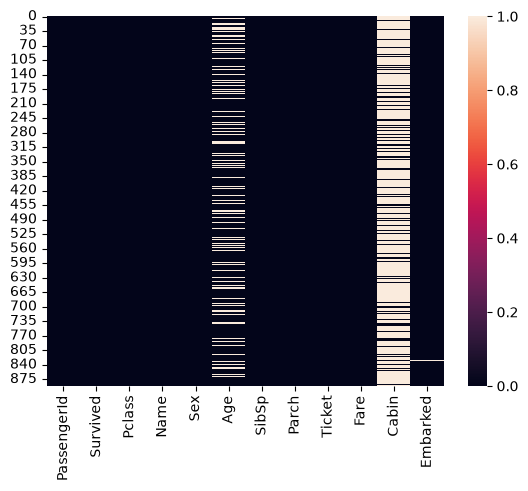

In [8]:
sns.heatmap(tdf.isnull())

<function matplotlib.pyplot.show(close=None, block=None)>

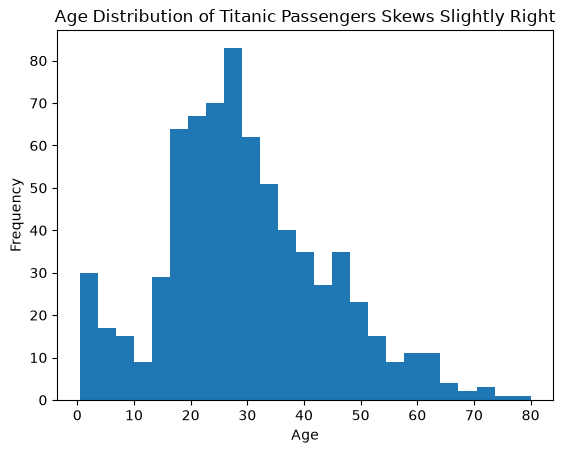

In [9]:
tdf["Age"].plot(kind="hist", bins=25)
plt.xlabel("Age")
plt.title("Age Distribution of Titanic Passengers Skews Slightly Right")
plt.show

In [10]:
fill_value = tdf["Age"].mean()
tdf["Age"] = tdf["Age"].fillna(fill_value)

print(fill_value)

29.69911764705882


## Cleaning Log:
- 177 rows were missing value for "Age" column
- because many rows were clustered around the mean value for "Age", mean value was imputed 
- ignored 687 missing rows for "cabin" because it is not relevant to the parts of the dataset being analyzed

In [11]:
tdf["Sex"].map({"male":0, "female": 1})

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    1
889    0
890    0
Name: Sex, Length: 891, dtype: int64

In [12]:
tdf["Sex"] = tdf["Sex"].map({"male":0, "female": 1})

In [13]:
X = tdf[["Pclass", "Sex", "Age"]]
y = tdf["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [14]:
print(len(X_train))
print(len(X_test))
print(len(y_train))
print(len(y_test))

623
268
623
268


In [15]:
knn = KNeighborsClassifier(n_neighbors=5)

In [16]:
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [17]:
predict = knn.predict(X_test)

In [18]:
print(knn.score(X_test, y_test))

0.7723880597014925


In [19]:
X_test[predict != y_test]

,Pclass,Sex,Age
709,3,0,29.699118
39,3,1,14.000000
300,3,1,29.699118
621,1,0,42.000000
653,3,1,29.699118
...,...,...,...
626,2,0,57.000000
449,1,0,52.000000
660,1,0,50.000000
804,3,0,27.000000


In [20]:
incorrect = X_test[predict != y_test]

In [21]:
for column in incorrect.columns:
    print(incorrect[column].value_counts())

Pclass
3    34
1    18
2     9
Name: count, dtype: int64
Sex
1    32
0    29
Name: count, dtype: int64
Age
29.699118    14
52.000000     3
38.000000     3
27.000000     3
19.000000     2
31.000000     2
18.000000     2
57.000000     2
30.000000     2
63.000000     2
32.000000     2
25.000000     2
14.000000     1
42.000000     1
34.000000     1
4.000000      1
58.000000     1
11.000000     1
30.500000     1
56.000000     1
9.000000      1
45.000000     1
40.000000     1
15.000000     1
44.000000     1
23.000000     1
6.000000      1
29.000000     1
7.000000      1
20.000000     1
24.000000     1
26.000000     1
62.000000     1
50.000000     1
Name: count, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

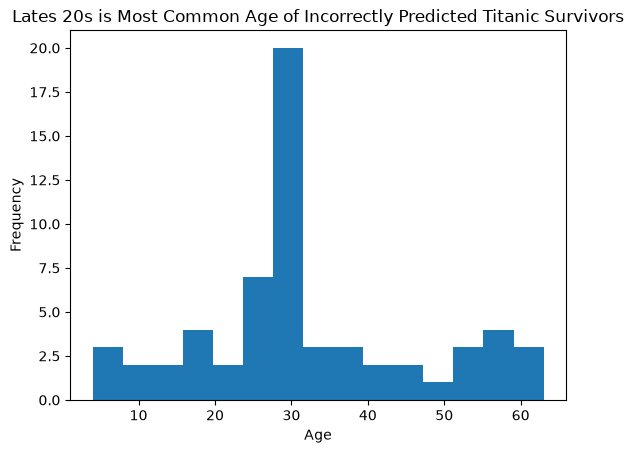

In [22]:
incorrect["Age"].plot(kind="hist", bins=15)
plt.xlabel("Age")
plt.title("Lates 20s is Most Common Age of Incorrectly Predicted Titanic Survivors")
plt.show

<p>It appears that the most common feature of an incorrectly predicted row is "Pclass", or the passenger's class on-board the sinking ship; the kNN model predicted incorrectly for members of class "3" most often. It is unclear why this error was so common.</p>

<p>Also of note: The model incorrectly predicted women's survivorship only slightly more frequently than that of men. With regards to age, the model failed most often in regards to passengers between roughly 25 and 35, by a large margin.</p>

<p>I consulted the pandas and NumPy User Guides:</p>

<p>https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.get_dummies.html <br>
https://pandas.pydata.org/docs/user_guide/basics.html <br>
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.value_counts.html <br>
https://numpy.org/doc/stable/user/basics.indexing.html</p>

Github Repo Url: https://github.com/journeyrahman/cs82a-portfolio